# Data Augmentation with `torchvision.transforms.v2`
### Representation Learning, Lecture 3: MNIST / Fashion-MNIST

> Adapted from Lightning AI's *Deep Learning Fundamentals*, Unit 7.5 Part 2, *Implementing Data Augmentations in PyTorch* (Sebastian Raschka) ([video](https://www.youtube.com/watch?v=DY905WdWv_M)).
> The original uses CIFAR-10 with the v1 `transforms` API. This version uses **MNIST / Fashion-MNIST at their native 28×28 resolution** with the **v2 API**. It also adds more augmentations, custom transforms, and a bridge to self-supervised learning.

**In this notebook**
1. Build train/test augmentation pipelines with `transforms.v2` (the video's pipeline, rewritten in v2)
2. Try a catalogue of geometric, photometric, occlusion, and automatic augmentations
3. Check whether an augmentation is **label-preserving** for a given dataset
4. Write your own augmentations by subclassing `v2.Transform`
5. Use batch-level augmentation (MixUp, CutMix) and two-view augmentation for SSL

## Why augment? A short formalization

Let $\mathcal{D}=\{(x_n,y_n)\}_{n=1}^{N}$ with $x_n\in\mathbb{R}^{C\times H\times W}$, and let $\mathcal{T}$ be a distribution over transformations $t:\mathbb{R}^{C\times H\times W}\to\mathbb{R}^{C\times H\times W}$.
Instead of plain empirical risk minimization, we minimize the **augmented** risk:

$$
\min_{\theta}\;\frac{1}{N}\sum_{n=1}^{N}\mathbb{E}_{t\sim\mathcal{T}}\Big[\ell\big(f_\theta(t(x_n)),\,y_n\big)\Big]
$$

In practice a fresh $t\sim\mathcal{T}$ is drawn **every time a sample is loaded**, so each epoch sees a new version of every image.

By choosing $\mathcal{T}$ we state which changes should *not* change the prediction. We inject the invariance $f_\theta(t(x))\approx f_\theta(x)$.
This only makes sense when $t$ is **label-preserving**, i.e. $y(t(x)) = y(x)$ (Section 7).

In self-supervised learning (from Lecture 4 on) there are no labels: the augmentations *are* the training signal. Two views $t_1(x)$ and $t_2(x)$ of the same image should get similar representations (Section 11).

## 1. Setup

In [ ]:
%pip install -q lightning   # Colab ships torch + torchvision, but not Lightning

In [ ]:
import lightning as L
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset, default_collate
from torchvision import datasets, tv_tensors
from torchvision.transforms import v2
from torchvision.utils import make_grid

print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | lightning {L.__version__}")

# Custom v2 transforms (Section 8) use the public API introduced in torchvision 0.21
tv_version = tuple(int(v) for v in torchvision.__version__.split("+")[0].split(".")[:2])
assert tv_version >= (0, 21), "Please upgrade: %pip install -U torchvision"

### Plotting helpers
Images take three forms in this notebook: `uint8` in $[0,255]$, `float` in $[0,1]$, and normalized `float` (after `Normalize`). `to_display` converts any of them back to $[0,1]$ for plotting.

In [3]:
def to_display(img):
    # Any image tensor -> float in [0, 1] (C x H x W) for plotting
    img = torch.as_tensor(img).detach().cpu()
    if img.dtype == torch.uint8:
        img = img.float() / 255
    elif img.min() < 0:                # only normalized images contain negative values
        img = img * STD + MEAN         # undo Normalize (MEAN/STD are computed in Section 4)
    return img.float().clamp(0, 1)


def show_grid(images, title, nrow=8):
    # Video-style grid of a batch (or list) of images
    images = [to_display(img) for img in images]
    n_rows = -(-len(images) // nrow)
    grid = make_grid(images, nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(0.8 * nrow, 0.8 * n_rows + 0.4))
    plt.axis("off")
    plt.title(title)
    plt.imshow(grid.permute(1, 2, 0))
    plt.show()


def show_table(rows, col_titles=None, title=None, size=1.0):
    # rows = {row_label: [img, img, ...]} -> one labelled row of images per entry
    n_rows, n_cols = len(rows), max(len(imgs) for imgs in rows.values())
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols + 1.5, size * n_rows), squeeze=False)
    for r, (label, imgs) in enumerate(rows.items()):
        for c, ax in enumerate(axes[r]):
            ax.set_xticks([])
            ax.set_yticks([])
            if c < len(imgs):
                ax.imshow(to_display(imgs[c])[0], cmap="gray", vmin=0, vmax=1)
            else:
                ax.axis("off")
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    for c, col_title in enumerate(col_titles or []):
        axes[0, c].set_title(col_title, fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def gallery(img, transforms, n=7):
    # Apply every transform n times to the same image: rows = transforms, columns = random draws
    rows = {name: [img] + [t(img) for _ in range(n)] for name, t in transforms.items()}
    show_table(rows, col_titles=["original"] + [f"draw {i + 1}" for i in range(n)])

## 2. Configuration: choose the dataset

In [4]:
DATASET = "MNIST"            # "MNIST" or "FashionMNIST"
DATA_PATH = "./data"
BATCH_SIZE = 64
NUM_WORKERS = 2              # free Colab has 2 CPU cores

# A mirrored shirt is still a shirt, but a mirrored "3" is not a digit
HFLIP_P = 0.5 if DATASET == "FashionMNIST" else 0.0

L.seed_everything(123)

Seed set to 123


123

## 3. DataModule

This plays the same role as `Cifar10DataModule` in the video. It downloads the data, splits train/validation, and builds the `DataLoader`s. Transforms are **passed in from outside**, so we can swap augmentation pipelines without touching the class.

**One fix compared with the original:** calling `random_split` on a single dataset object gives the validation split the *training* transforms, so validation images get augmented too.
Here, train and validation are two dataset objects over the same files (one with `train_transform`, one with `test_transform`), split with the same indices.

In [5]:
DATASET_CLASSES = {"MNIST": datasets.MNIST, "FashionMNIST": datasets.FashionMNIST}

# Default when no transform is given: image -> float tensor in [0, 1], no augmentation
to_float_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])


class MnistDataModule(L.LightningDataModule):
    def __init__(self, dataset_name="MNIST", data_path="./data", batch_size=64, num_workers=0,
                 train_transform=None, test_transform=None, n_val=5000):
        super().__init__()
        self.dataset_cls = DATASET_CLASSES[dataset_name]
        self.data_path = data_path
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.train_transform = train_transform if train_transform is not None else to_float_tensor
        self.test_transform = test_transform if test_transform is not None else to_float_tensor
        self.n_val = n_val

    def prepare_data(self):
        # download once
        self.dataset_cls(root=self.data_path, train=True, download=True)
        self.dataset_cls(root=self.data_path, train=False, download=True)

    def setup(self, stage=None):
        train_aug = self.dataset_cls(root=self.data_path, train=True, transform=self.train_transform)
        train_clean = self.dataset_cls(root=self.data_path, train=True, transform=self.test_transform)
        idx = torch.randperm(len(train_aug), generator=torch.Generator().manual_seed(42)).tolist()
        self.train = Subset(train_aug, idx[self.n_val:])     # augmented
        self.valid = Subset(train_clean, idx[:self.n_val])   # never augmented
        self.test = self.dataset_cls(root=self.data_path, train=False, transform=self.test_transform)
        self.classes = [c.split(" - ")[0] for c in self.test.classes]   # MNIST: "3 - three" -> "3"

    def _loader(self, dataset, shuffle):
        return DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle,
                          drop_last=shuffle, num_workers=self.num_workers)

    def train_dataloader(self):
        return self._loader(self.train, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.valid, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test, shuffle=False)

## 4. A first look at the training images

As in the video, we load one batch **without augmentation**. `v2.ToImage()` alone gives the images as stored: `uint8`, shape $1\times28\times28$, values in $[0,255]$.

torch.Size([64, 1, 28, 28]) torch.uint8 values in [0, 255]


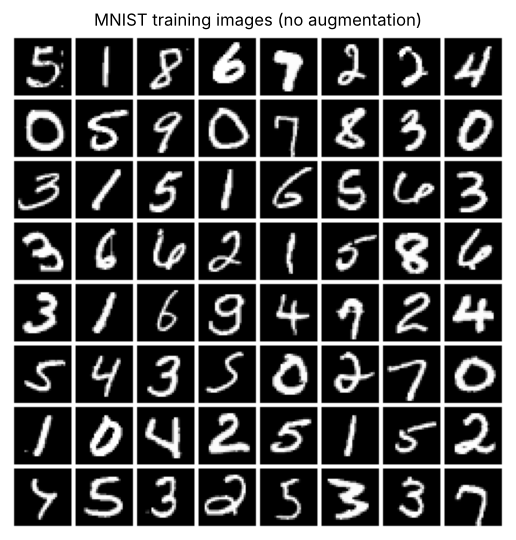

In [6]:
dm = MnistDataModule(DATASET, DATA_PATH, BATCH_SIZE, NUM_WORKERS, train_transform=v2.ToImage())
dm.prepare_data()
dm.setup()

images, labels = next(iter(dm.train_dataloader()))
print(images.shape, images.dtype, f"values in [{images.min()}, {images.max()}]")
show_grid(images, f"{DATASET} training images (no augmentation)")

### Normalization statistics
`Normalize` standardizes every pixel: $\hat{x} = (x-\mu)/\sigma$, with

$$
\mu=\frac{1}{NHW}\sum_{n,i,j}x_{n,ij},\qquad
\sigma^2=\frac{1}{NHW}\sum_{n,i,j}\big(x_{n,ij}-\mu\big)^2 .
$$

The video used $\mu=\sigma=0.5$ (mapping $[0,1]\to[-1,1]$). Here we compute the actual statistics, **on the training split only**.

In [7]:
train_pixels = dm.train.dataset.data[dm.train.indices].float() / 255   # (55000, 28, 28)
MEAN, STD = train_pixels.mean().item(), train_pixels.std().item()
del train_pixels
print(f"{DATASET}: mean = {MEAN:.4f}, std = {STD:.4f}")

MNIST: mean = 0.1307, std = 0.3081


## 5. The video's augmentation pipeline, rewritten in v2

| Video (v1, CIFAR-10 $3\times32\times32$) | This notebook (v2, $1\times28\times28$) | Why |
|---|---|---|
| `ToPILImage()` | not needed | v2 works directly on tensors (and PIL images) |
| `Resize((150, 150))` → `RandomCrop((128, 128))` | `Resize((32, 32))` → `RandomCrop((28, 28))` | same idea at native scale: upsample slightly, crop a random window |
| `RandomHorizontalFlip(p=0.2)` | `RandomHorizontalFlip(p=HFLIP_P)` | off for digits (Section 7) |
| `ColorJitter(brightness, contrast, saturation, hue)` | `ColorJitter(brightness, contrast)` | saturation and hue are undefined for one channel |
| `ToTensor()` | `ToImage()` + `ToDtype(torch.float32, scale=True)` | `ToTensor` is deprecated in v2; dtype and scaling become explicit |
| `Normalize((0.5,)*3, (0.5,)*3)` | `Normalize((MEAN,), (STD,))` | dataset statistics, one channel |

**v2 rule of thumb:** augment while the image is still `uint8`, then convert to float, then normalize. Many ops are faster on `uint8`, and some (`Posterize`, `Equalize`, `Solarize` thresholds) assume it.

In [8]:
train_transform = v2.Compose([
    v2.ToImage(),                                    # -> tv_tensors.Image, uint8, C x H x W
    v2.Resize((32, 32)),                             # video: Resize((150, 150))
    v2.RandomCrop((28, 28)),                         # video: RandomCrop((128, 128)) -> random translation
    v2.RandomHorizontalFlip(p=HFLIP_P),              # video: p=0.2
    v2.ColorJitter(brightness=0.1, contrast=0.1),    # video also had saturation & hue (RGB only)
    v2.ToDtype(torch.float32, scale=True),           # uint8 [0, 255] -> float32 [0, 1]
    v2.Normalize(mean=(MEAN,), std=(STD,)),          # (x - mu) / sigma
])

test_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((32, 32)),
    v2.CenterCrop((28, 28)),                         # deterministic: the same crop every time
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(MEAN,), std=(STD,)),
])

Same as the video: apply each pipeline **image by image** to the batch we loaded, then compare.
`train_transform` is random (a new crop and brightness every call). `test_transform` is deterministic. We never augment at evaluation time.

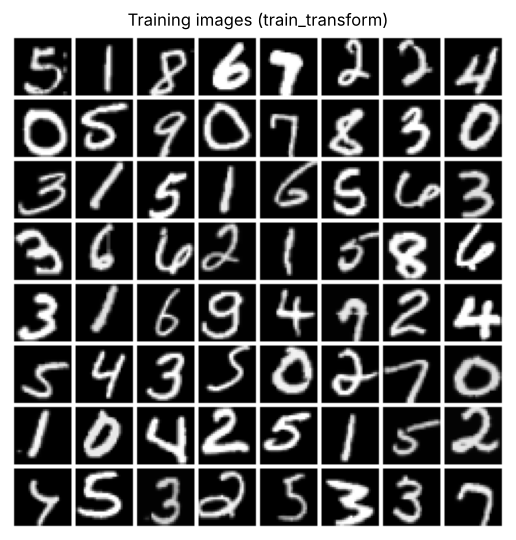

In [9]:
train_batch = [train_transform(img) for img in images]
show_grid(train_batch, "Training images (train_transform)")

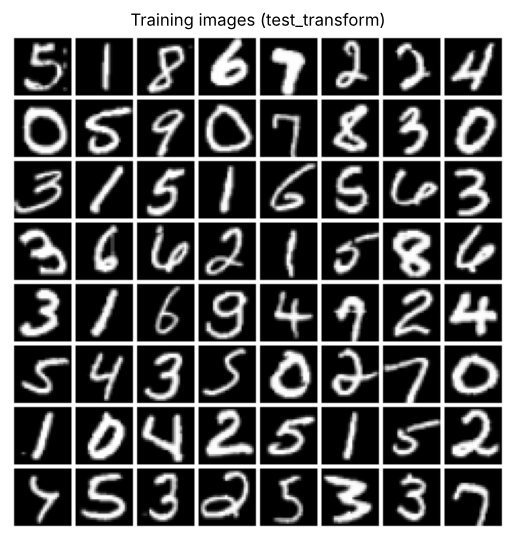

In [10]:
test_batch = [test_transform(img) for img in images]
show_grid(test_batch, "Training images (test_transform)")

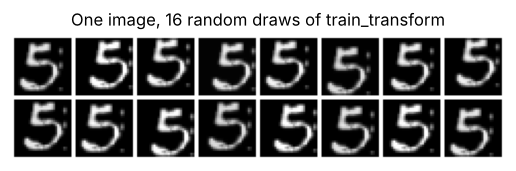

In [11]:
img = images[0]   # one uint8 image, reused in the galleries below
show_grid([train_transform(img) for _ in range(16)], "One image, 16 random draws of train_transform")

### Watch out: per-sample vs. per-batch randomness
If you pass a **batch** tensor $(B,C,H,W)$ to a v2 transform, it draws the random parameters **once** and applies the same transformation to all $B$ images.
That is why the video (and the cells above) apply transforms image by image. It is also why augmentation normally lives in the `Dataset` (`transform=`): there, `__getitem__` calls it once per sample.

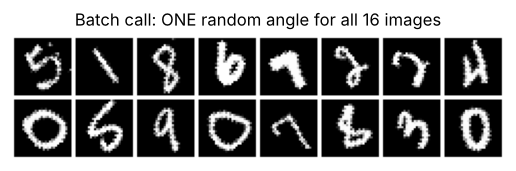

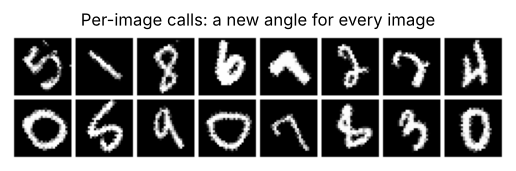

In [12]:
rotate = v2.RandomRotation(degrees=(20, 60))   # always 20°-60°, so the effect is visible
show_grid(rotate(images[:16]), "Batch call: ONE random angle for all 16 images")
show_grid([rotate(x) for x in images[:16]], "Per-image calls: a new angle for every image")

## 6. More built-in augmentations

Each gallery row applies one transform 7 times to the same image, so you can see its *distribution* $\mathcal{T}$, not just a single draw.

### 6.1 Geometric
* **Affine:** a pixel location $\mathbf{p}=(u,v)^\top$ moves to $\mathbf{p}'=A\mathbf{p}+\mathbf{b}$, with

$$
A = s\begin{pmatrix}\cos\phi & -\sin\phi\\ \sin\phi & \cos\phi\end{pmatrix}\begin{pmatrix}1 & \tan\psi\\ 0 & 1\end{pmatrix},
$$

  where $\phi$ is rotation, $s$ scale, $\psi$ shear, and $\mathbf{b}$ translation. Output pixels are interpolated from the inverse map.
* **Perspective:** a homography $\tilde{\mathbf{p}}'\sim H\tilde{\mathbf{p}}$ in homogeneous coordinates ($H\in\mathbb{R}^{3\times3}$, 8 degrees of freedom).
* **Elastic** (Simard et al., 2003, proposed *for MNIST*): a smooth random displacement field
  $\Delta=\alpha\,(G_\sigma * U)$, $U\sim\mathcal{U}(-1,1)^{2\times H\times W}$, gives $x'(\mathbf{p})=x(\mathbf{p}+\Delta(\mathbf{p}))$. It mimics the natural wobble of handwriting.
* **RandomResizedCrop:** crop a random area fraction $a\sim\mathcal{U}[a_{\min},1]$ (and aspect ratio), then resize back to $28\times28$. This is the key augmentation in SimCLR.

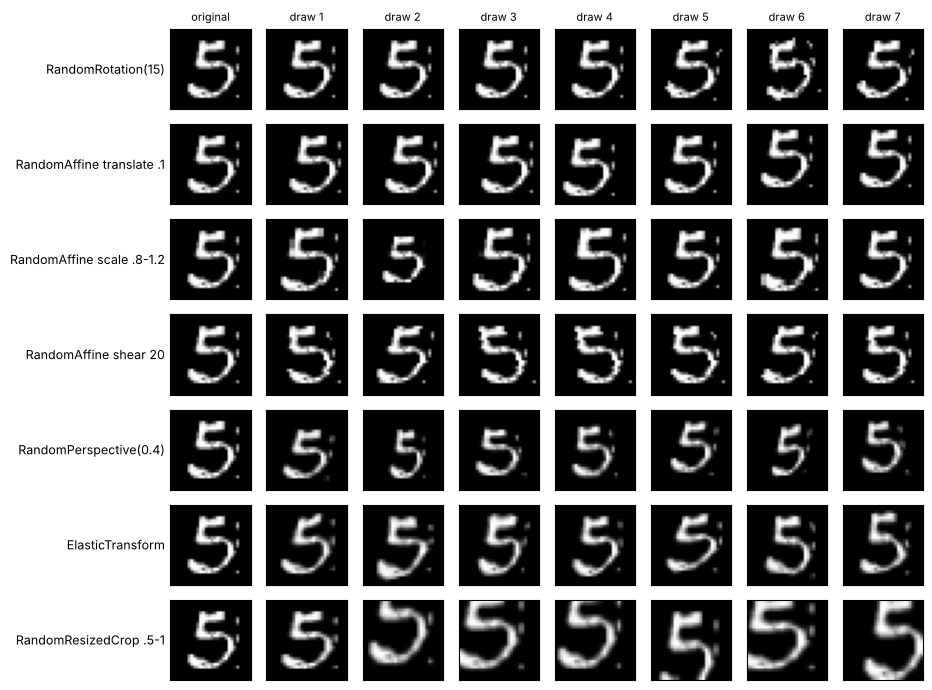

In [13]:
geometric = {
    "RandomRotation(15)":        v2.RandomRotation(degrees=15),
    "RandomAffine translate .1": v2.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    "RandomAffine scale .8-1.2": v2.RandomAffine(degrees=0, scale=(0.8, 1.2)),
    "RandomAffine shear 20":     v2.RandomAffine(degrees=0, shear=20),
    "RandomPerspective(0.4)":    v2.RandomPerspective(distortion_scale=0.4, p=1.0),
    "ElasticTransform":          v2.ElasticTransform(alpha=30.0, sigma=4.0),
    "RandomResizedCrop .5-1":    v2.RandomResizedCrop(28, scale=(0.5, 1.0)),
}
gallery(img, geometric)

### 6.2 Photometric (intensity)
For pixel intensities $x\in[0,255]$:
* **Brightness:** $x'=b\,x$, with $b\sim\mathcal{U}[1-\beta,1+\beta]$. **Contrast:** $x'=c\,x+(1-c)\,\bar{x}$, where $\bar{x}$ is the mean intensity.
* **Gaussian blur:** $x'=G_\sigma * x$, with $G_\sigma(u,v)\propto\exp\!\big(-\tfrac{u^2+v^2}{2\sigma^2}\big)$.
* **Sharpness:** blend between a smoothed image and the original, extrapolating away from the smooth version.
* **Invert:** $x'=255-x$. **Posterize:** keep $b$ bits, $x'=2^{8-b}\lfloor x/2^{8-b}\rfloor$. **Solarize:** invert pixels above a threshold $\tau$.
* **Equalize:** histogram equalization, mapping intensities through the empirical CDF.

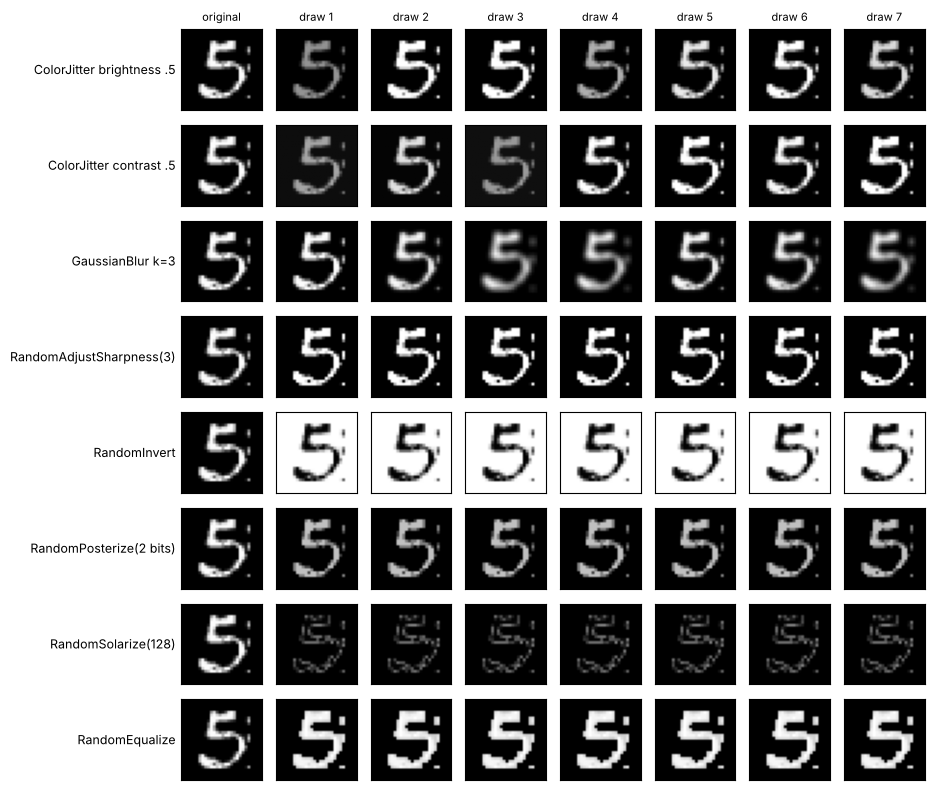

In [14]:
photometric = {
    "ColorJitter brightness .5": v2.ColorJitter(brightness=0.5),
    "ColorJitter contrast .5":   v2.ColorJitter(contrast=0.5),
    "GaussianBlur k=3":          v2.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5)),
    "RandomAdjustSharpness(3)":  v2.RandomAdjustSharpness(sharpness_factor=3, p=1.0),
    "RandomInvert":              v2.RandomInvert(p=1.0),
    "RandomPosterize(2 bits)":   v2.RandomPosterize(bits=2, p=1.0),
    "RandomSolarize(128)":       v2.RandomSolarize(threshold=128, p=1.0),
    "RandomEqualize":            v2.RandomEqualize(p=1.0),
}
gallery(img, photometric)

In [15]:
# Color augmentations silently do nothing on grayscale images
hue_sat = v2.ColorJitter(saturation=0.9, hue=0.5)
print("Did hue/saturation jitter change the image?", not torch.equal(hue_sat(img), img))

Did hue/saturation jitter change the image? False


### 6.3 Occlusion
**Random Erasing / Cutout** (Zhong et al., 2020; DeVries & Taylor, 2017) replaces a random rectangle with a constant. This forces the model to use *all* parts of the object, not one discriminative patch.
On MNIST the background is 0, so a black box only shows when it covers a stroke. A white box (255) is always visible.

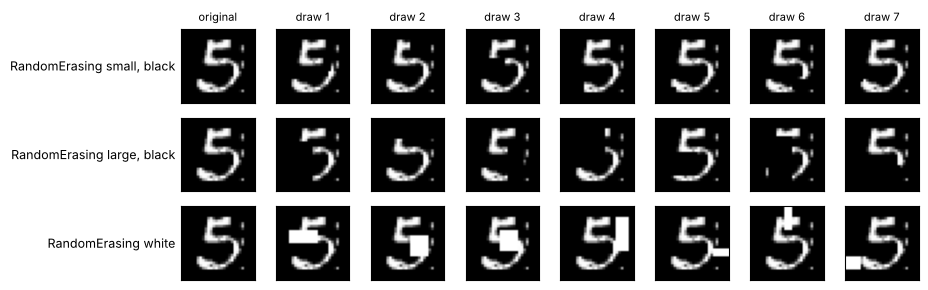

In [16]:
occlusion = {
    "RandomErasing small, black": v2.RandomErasing(p=1.0, scale=(0.02, 0.1), value=0),
    "RandomErasing large, black": v2.RandomErasing(p=1.0, scale=(0.1, 0.3), value=0),
    "RandomErasing white":        v2.RandomErasing(p=1.0, scale=(0.02, 0.1), value=255),
}
gallery(img, occlusion)

### 6.4 Putting it together: a stronger training pipeline
`RandomApply([...], p)` applies its transforms with probability $p$. `RandomChoice([...])` picks one of them per call.
`RandomErasing` is placed after `Normalize`, so the erased box gets the value $0$ in normalized space, which corresponds to the mean intensity.

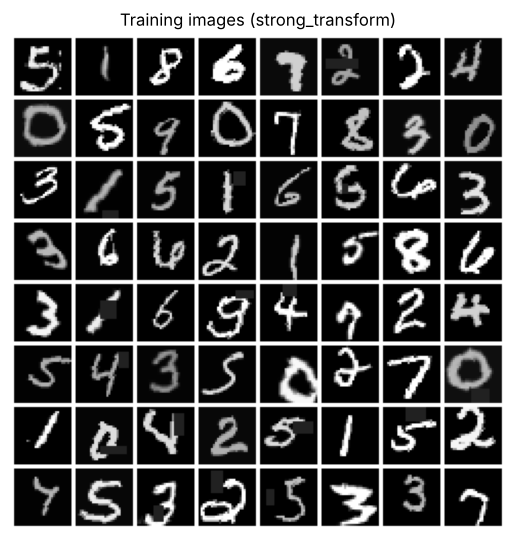

In [17]:
strong_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=5),
    v2.RandomApply([v2.ElasticTransform(alpha=30.0, sigma=4.0)], p=0.3),
    v2.RandomHorizontalFlip(p=HFLIP_P),
    v2.ColorJitter(brightness=0.3, contrast=0.3),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(MEAN,), std=(STD,)),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
show_grid([strong_transform(x) for x in images], "Training images (strong_transform)")

## 7. Is my augmentation label-preserving?

An augmentation is only valid if $y(t(x)) = y(x)$. Whether that holds **depends on the dataset**.
Below: one test image per class under transforms that are fine for some datasets and harmful for others.

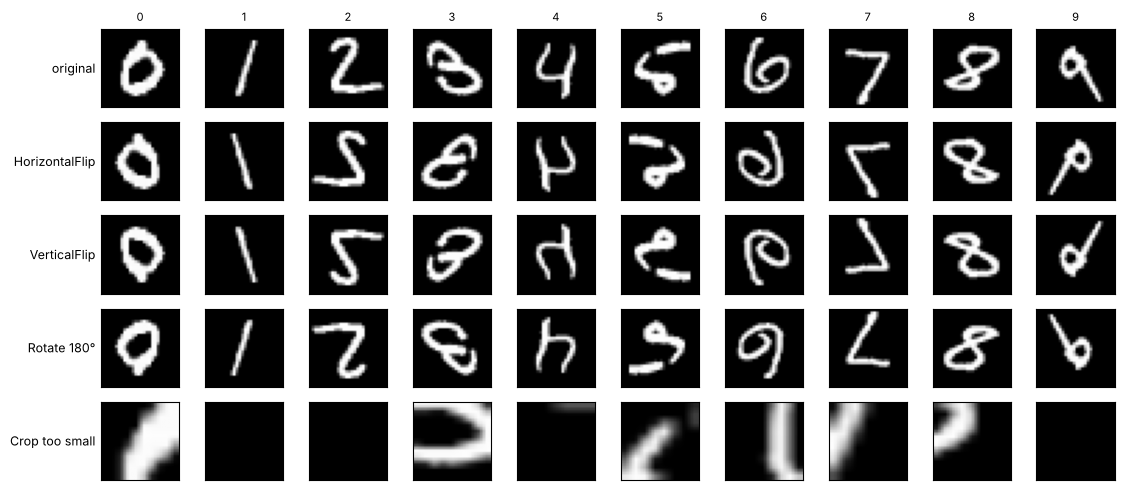

In [18]:
first_of_class = [(dm.test.targets == c).nonzero()[0].item() for c in range(10)]
examples = [dm.test.data[i].unsqueeze(0) for i in first_of_class]       # uint8, 1 x 28 x 28

too_small_crop = v2.RandomResizedCrop(28, scale=(0.05, 0.15))
show_table({
    "original":       examples,
    "HorizontalFlip": [v2.functional.horizontal_flip(x) for x in examples],
    "VerticalFlip":   [v2.functional.vertical_flip(x) for x in examples],
    "Rotate 180°":    [v2.functional.rotate(x, 180) for x in examples],
    "Crop too small": [too_small_crop(x) for x in examples],
}, col_titles=dm.classes)

**Discussion**
* **MNIST:** flips and large rotations turn digits into non-digits, or **into other digits**. A "6" rotated by 180° is a "9" with the label still "6", which is pure label noise. Keep rotations small ($|\phi|\lesssim15^\circ$) and do not flip.
* **Fashion-MNIST:** horizontal flips are label-preserving (clothing is roughly left/right symmetric). Vertical flips keep the label but create upside-down items that never occur at test time, so they waste model capacity on an irrelevant invariance.
* **Both:** a crop that is too small removes the content that defines the class.

$\mathcal{T}$ is a **modelling choice that encodes prior knowledge** about the data, and augmentation *strength* is a hyperparameter. That is what the ablation study measures.

## 8. Custom augmentations: subclassing `v2.Transform`

```python
class MyTransform(v2.Transform):
    def __init__(self, ...):                 # store hyperparameters
        super().__init__()
    def make_params(self, flat_inputs):      # draw the random numbers ONCE per call -> dict
        return {...}
    def transform(self, inpt, params):       # apply to ONE input, using those params
        return ...
```

* **Do not override `forward()`.** It flattens the inputs (e.g. image + segmentation mask + boxes), calls `make_params` **once**, then calls `transform` on every input. An image and its mask therefore get the *same* random crop or flip.
* **Return the type you received.** Plain torch ops (`+`, `masked_fill`, …) drop the `tv_tensors.Image` type, so we re-attach it with `tv_tensors.wrap(out, like=inpt)`.
* In torchvision < 0.21 these two methods were private: `_get_params` and `_transform`.
* Our transforms expect **float images in $[0,1]$**. Place them after `ToDtype(torch.float32, scale=True)` and before `Normalize`.

In [19]:
def check_float_image(inpt, transform):
    if not (isinstance(inpt, torch.Tensor) and inpt.is_floating_point()):
        raise TypeError(f"{type(transform).__name__} expects a float image in [0, 1]; "
                        "place it after v2.ToDtype(torch.float32, scale=True).")


class AddGaussianNoise(v2.Transform):
    # x' = clip(x + eps, 0, 1),  eps ~ N(0, sigma^2 I),  sigma ~ U[sigma_min, sigma_max]

    def __init__(self, sigma=(0.05, 0.2), p=0.5):
        super().__init__()
        self.sigma = sigma
        self.p = p

    def make_params(self, flat_inputs):
        return {
            "apply": torch.rand(1).item() < self.p,
            "sigma": torch.empty(1).uniform_(*self.sigma).item(),
        }

    def transform(self, inpt, params):
        if not params["apply"]:
            return inpt
        check_float_image(inpt, self)
        out = (inpt + params["sigma"] * torch.randn_like(inpt)).clamp(0.0, 1.0)
        return tv_tensors.wrap(out, like=inpt)

### Salt-and-pepper noise
Impulse noise that sets random pixels to the extremes, like dead or saturated sensor pixels and scanning dust.
With noise amount $a$, salt ratio $s$, and one uniform draw $u_{ij}\sim\mathcal{U}(0,1)$ per pixel:

$$
x'_{ij}=
\begin{cases}
1 & u_{ij} < a\,s \quad\text{(salt)}\\
0 & a\,s \le u_{ij} < a \quad\text{(pepper)}\\
x_{ij} & \text{otherwise}
\end{cases}
$$

In [20]:
class SaltAndPepperNoise(v2.Transform):
    def __init__(self, amount=(0.02, 0.1), salt_ratio=0.5, p=0.5):
        super().__init__()
        self.amount = amount          # range for a (fraction of corrupted pixels)
        self.salt_ratio = salt_ratio  # s (fraction of corrupted pixels set to white)
        self.p = p

    def make_params(self, flat_inputs):
        return {
            "apply": torch.rand(1).item() < self.p,
            "amount": torch.empty(1).uniform_(*self.amount).item(),
        }

    def transform(self, inpt, params):
        if not params["apply"]:
            return inpt
        check_float_image(inpt, self)
        a, s = params["amount"], self.salt_ratio
        u = torch.rand(inpt.shape[-2:], device=inpt.device)       # one draw per pixel, shared by channels
        out = inpt.masked_fill(u < a * s, 1.0)                    # salt
        out = out.masked_fill((u >= a * s) & (u < a), 0.0)        # pepper
        return tv_tensors.wrap(out, like=inpt)

### Random stroke width (grayscale morphology)
Different pens give different stroke widths. **Dilation** thickens bright strokes and **erosion** thins them. With a $k\times k$ structuring element $B$:

$$
(x\oplus B)(i,j)=\max_{(u,v)\in B}x(i+u,\,j+v),\qquad
(x\ominus B)(i,j)=\min_{(u,v)\in B}x(i+u,\,j+v) = -\big((-x)\oplus B\big)(i,j)
$$

Both are a stride-1 max-pool, so they take one line each in PyTorch. On Fashion-MNIST the same operation thickens or thins edges and textures.
`make_params` decides *which* operation and kernel size to use, so all inputs of one sample get the same choice.
MNIST strokes are only 2–3 px wide: $k=2$ is safe, while $k=3$ erosion can erase a digit completely.

In [21]:
class RandomStrokeWidth(v2.Transform):
    def __init__(self, kernel_sizes=(2,), p=0.5):   # k=3 erosion erases thin MNIST strokes (try it!)
        super().__init__()
        self.kernel_sizes = kernel_sizes
        self.p = p

    def make_params(self, flat_inputs):
        return {
            "apply": torch.rand(1).item() < self.p,
            "op": "dilate" if torch.rand(1).item() < 0.5 else "erode",
            "k": self.kernel_sizes[torch.randint(len(self.kernel_sizes), (1,)).item()],
        }

    def transform(self, inpt, params):
        if not params["apply"]:
            return inpt
        check_float_image(inpt, self)
        k = params["k"]
        lo, hi = (k - 1) // 2, k // 2                              # 'same' padding, also for even k
        sign = 1.0 if params["op"] == "dilate" else -1.0           # erosion = -dilation(-x)
        padded = F.pad(sign * inpt, (lo, hi, lo, hi), mode="replicate")
        out = sign * F.max_pool2d(padded, kernel_size=k, stride=1)
        return tv_tensors.wrap(out, like=inpt)

### Sanity checks
Test your own transforms before training with them. Here we check that:
1. the noise level matches the built-in `v2.GaussianNoise`,
2. `p=0` really is the identity,
3. the output keeps the input's type, dtype and shape.

In [22]:
gray = tv_tensors.Image(torch.full((1, 28, 28), 0.5))

ours = AddGaussianNoise(sigma=(0.1, 0.1), p=1.0)(gray)
builtin = v2.GaussianNoise(sigma=0.1)(gray)
print(f"noise std (target 0.100): ours {(ours - gray).std():.3f} | built-in {(builtin - gray).std():.3f}")

for t in [AddGaussianNoise(p=0.0), SaltAndPepperNoise(p=0.0), RandomStrokeWidth(p=0.0)]:
    assert torch.equal(t(gray), gray), type(t).__name__

for t in [AddGaussianNoise(p=1.0), SaltAndPepperNoise(p=1.0), RandomStrokeWidth(p=1.0)]:
    out = t(gray)
    print(f"{type(t).__name__:20s} -> {type(out).__name__}, {out.dtype}, {tuple(out.shape)}")

noise std (target 0.100): ours 0.102 | built-in 0.105
AddGaussianNoise     -> Image, torch.float32, (1, 28, 28)
SaltAndPepperNoise   -> Image, torch.float32, (1, 28, 28)
RandomStrokeWidth    -> Image, torch.float32, (1, 28, 28)


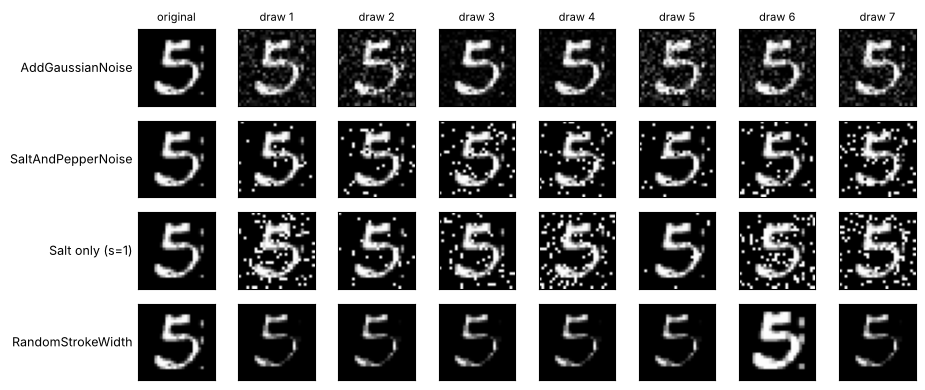

In [23]:
img_float = v2.ToDtype(torch.float32, scale=True)(v2.ToImage()(img))    # float image in [0, 1]

custom = {
    "AddGaussianNoise":       AddGaussianNoise(sigma=(0.05, 0.25), p=1.0),
    "SaltAndPepperNoise":     SaltAndPepperNoise(amount=(0.02, 0.15), p=1.0),
    "Salt only (s=1)":        SaltAndPepperNoise(amount=(0.02, 0.15), salt_ratio=1.0, p=1.0),
    "RandomStrokeWidth":      RandomStrokeWidth(p=1.0),
}
gallery(img_float, custom)

### Custom transforms inside a pipeline and a `DataLoader`
Custom transforms compose with built-in ones like any other v2 transform.

> **Note on `num_workers > 0`:** worker processes must be able to import (pickle) your classes. On Colab/Linux, classes defined in the notebook work. On Windows/macOS, move them into a `.py` file.

torch.Size([64, 1, 28, 28]) torch.float32


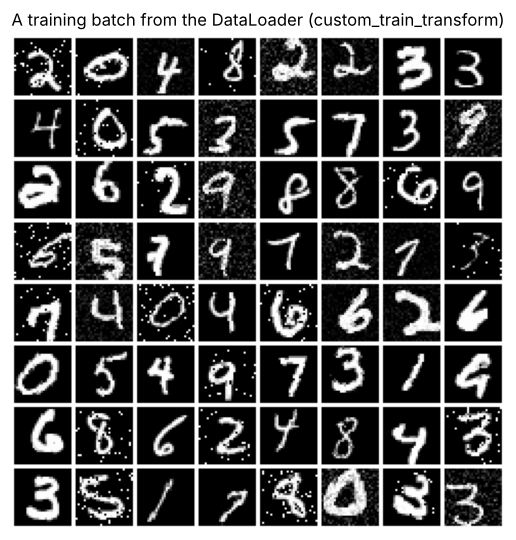

In [24]:
custom_train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    v2.ToDtype(torch.float32, scale=True),
    RandomStrokeWidth(p=0.3),
    v2.RandomApply([v2.RandomChoice([AddGaussianNoise(p=1.0), SaltAndPepperNoise(p=1.0)])], p=0.5),
    v2.Normalize(mean=(MEAN,), std=(STD,)),
])

dm_custom = MnistDataModule(DATASET, DATA_PATH, BATCH_SIZE, NUM_WORKERS,
                            train_transform=custom_train_transform, test_transform=test_transform)
dm_custom.setup()
x, y = next(iter(dm_custom.train_dataloader()))
print(x.shape, x.dtype)
show_grid(x, "A training batch from the DataLoader (custom_train_transform)")

## 9. Automatic augmentation policies

Instead of hand-designing $\mathcal{T}$, these methods sample from a fixed pool $\mathcal{O}$ of operations (rotate, shear, translate, posterize, solarize, contrast, …):

* **AutoAugment** (Cubuk et al., 2019): a policy *learned* with reinforcement learning on a proxy task. It consists of sub-policies of 2 ops, each with a probability and magnitude. torchvision ships the ImageNet, CIFAR-10 and **SVHN** (house-number digits) policies.
* **RandAugment** (Cubuk et al., 2020): no search. $t=o_N\circ\cdots\circ o_1$, $o_k\overset{\text{iid}}{\sim}\mathcal{U}(\mathcal{O})$, with one global magnitude $M$. Two hyperparameters: $N$ and $M$.
* **TrivialAugment** (Müller & Hutter, 2021): $N=1$ and magnitude $m\sim\mathcal{U}\{0,\dots,30\}$. No hyperparameters at all.
* **AugMix** (Hendrycks et al., 2020): mixes $k$ random augmentation chains,
  $x_{\text{aug}}=m\,x+(1-m)\sum_{i=1}^{k}w_i\,\text{chain}_i(x)$, with $(w_1,\dots,w_k)\sim\text{Dir}(\alpha)$ and $m\sim\text{Beta}(\alpha,\alpha)$.

These policies were tuned on natural RGB images. Their color ops do nothing on grayscale, `TrivialAugmentWide` rotates by up to 135° (6↔9!), and some draws remove the digit entirely.
They operate on `uint8` images, so place them **before** `ToDtype`.

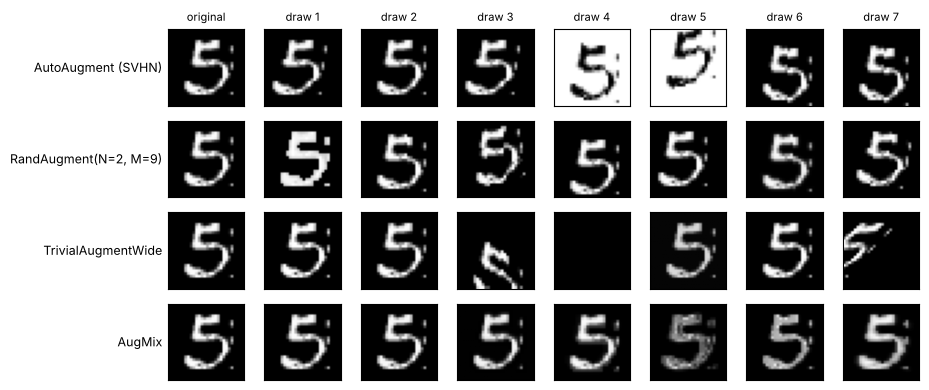

In [25]:
auto = {
    "AutoAugment (SVHN)":    v2.AutoAugment(v2.AutoAugmentPolicy.SVHN),
    "RandAugment(N=2, M=9)": v2.RandAugment(num_ops=2, magnitude=9),
    "TrivialAugmentWide":    v2.TrivialAugmentWide(),
    "AugMix":                v2.AugMix(),
}
gallery(img, auto)

## 10. Batch-level augmentation: MixUp and CutMix

These need **two** images, so they operate on a *batch* after the `DataLoader` and also mix the **labels** (one-hot $y$):

* **MixUp** (Zhang et al., 2018): $\lambda\sim\text{Beta}(\alpha,\alpha)$,
  $\;\tilde{x}=\lambda x_i+(1-\lambda)x_j$, $\;\tilde{y}=\lambda y_i+(1-\lambda)y_j$.
* **CutMix** (Yun et al., 2019): a random box mask $M\in\{0,1\}^{H\times W}$,
  $\;\tilde{x}=M\odot x_i+(1-M)\odot x_j$, $\;\tilde{y}=\lambda y_i+(1-\lambda)y_j$, where $\lambda$ is the fraction of pixels taken from $x_i$.

The loss uses the soft target, $\ell=-\sum_k\tilde{y}_k\log\hat{p}_k$. `F.cross_entropy(logits, y_soft)` accepts class probabilities as the target.
In torchvision, one $\lambda$ is drawn per batch, and $x_i$ is mixed with its neighbor in the batch.

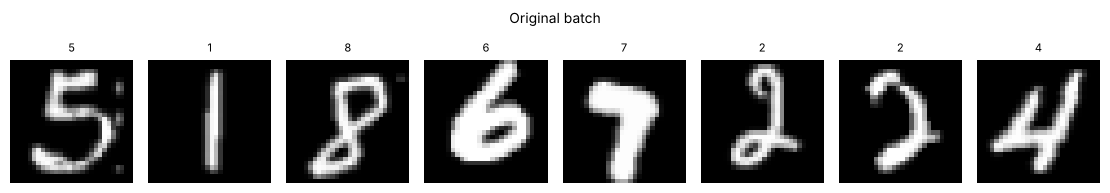

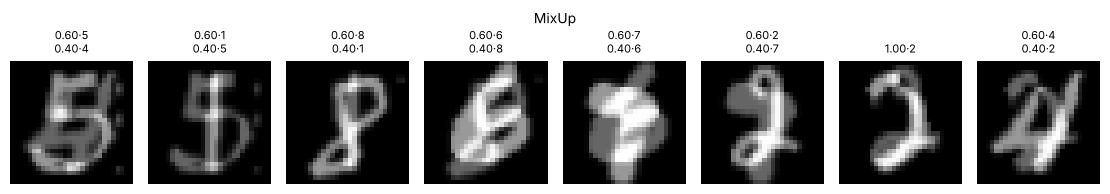

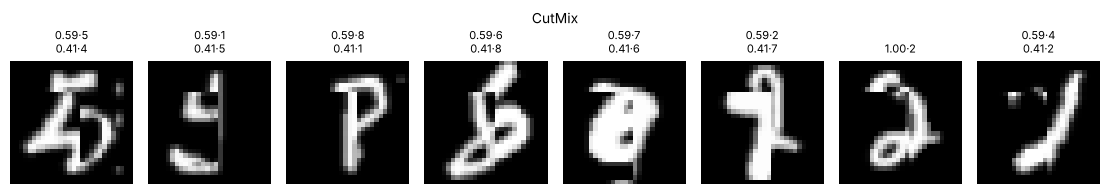

In [26]:
def show_images(imgs, titles, suptitle=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(1.4 * len(imgs), 2.0))
    for ax, im, t in zip(axes, imgs, titles):
        ax.imshow(to_display(im)[0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(t, fontsize=8)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()


def describe(soft_label):
    weights, ks = soft_label.topk(2)
    return "\n".join(f"{w:.2f}·{dm.classes[k]}" for w, k in zip(weights.tolist(), ks.tolist()) if w > 0.005)


mixup = v2.MixUp(alpha=1.0, num_classes=10)
cutmix = v2.CutMix(alpha=1.0, num_classes=10)

torch.manual_seed(1)                                              # reproducible example; rerun without it to see other λ
clean_x, clean_y = torch.stack(test_batch[:8]), labels[:8]      # normalized, no augmentation
show_images(clean_x, [dm.classes[k] for k in clean_y], "Original batch")
for name, mix in [("MixUp", mixup), ("CutMix", cutmix)]:
    x_mix, y_mix = mix(clean_x, clean_y)                         # y_mix: (8, 10) soft labels
    show_images(x_mix, [describe(t) for t in y_mix], name)

**Where to put it in a training pipeline:** in the training `DataLoader`'s `collate_fn` (as below), or at the start of `training_step`. Never in the validation or test loaders.

In [27]:
mix_either = v2.RandomChoice([mixup, cutmix])

def mix_collate(batch):
    return mix_either(*default_collate(batch))

mix_loader = DataLoader(dm_custom.train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=mix_collate)
xb, yb = next(iter(mix_loader))
print("images:", tuple(xb.shape), "| soft labels:", tuple(yb.shape), "| rows sum to:", yb.sum(dim=1)[:4].tolist())

images: (64, 1, 28, 28) | soft labels: (64, 10) | rows sum to: [1.0, 1.0, 1.0, 1.0]


## 11. Bridge to self-supervised learning: two views of the same image

In SSL there are no labels, and augmentation creates the learning signal. For each image, draw two independent transformations $t_1,t_2\sim\mathcal{T}$:

$$
\tilde{x}^{(1)}=t_1(x),\qquad \tilde{x}^{(2)}=t_2(x)\qquad\text{(a positive pair)}
$$

An encoder $f_\theta$ and a projection head $g_\phi$ give $z^{(v)}=g_\phi\big(f_\theta(\tilde{x}^{(v)})\big)$. Training pulls the two embeddings together, e.g. by maximizing

$$
\operatorname{sim}\big(z^{(1)},z^{(2)}\big)=\frac{z^{(1)\top}z^{(2)}}{\lVert z^{(1)}\rVert\,\lVert z^{(2)}\rVert}.
$$

**Whatever $\mathcal{T}$ changes, the representation learns to ignore.** $\mathcal{T}$ defines the invariances (Tian et al., 2020).
SSL pipelines are therefore much **stronger** than supervised ones; SimCLR uses random resized crops, color distortion and blur.
Pulling views together alone has a trivial solution, $f_\theta(x)=c$ for all $x$ (**collapse**). How to avoid it is the story of Lectures 4–8.

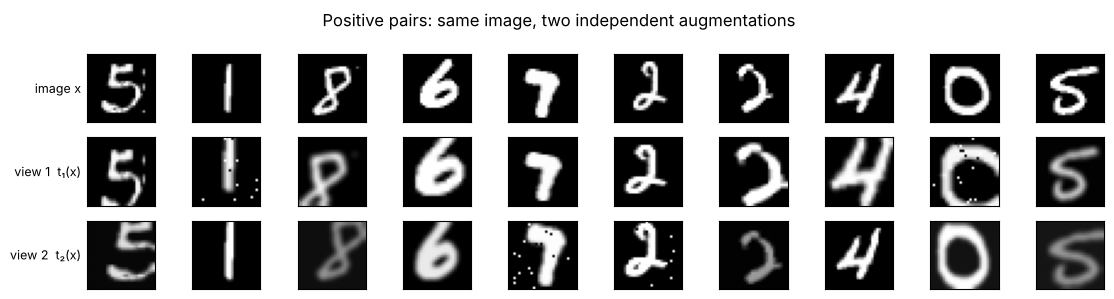

In [28]:
class TwoViews:
    # Wrap a transform so that every call returns two independently augmented views
    def __init__(self, transform):
        self.transform = transform

    def __call__(self, x):
        return self.transform(x), self.transform(x)


ssl_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(28, scale=(0.4, 1.0)),
    v2.RandomHorizontalFlip(p=HFLIP_P),
    v2.RandomApply([v2.ColorJitter(brightness=0.4, contrast=0.4)], p=0.8),
    v2.RandomApply([v2.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0))], p=0.5),
    v2.ToDtype(torch.float32, scale=True),
    SaltAndPepperNoise(amount=(0.01, 0.05), p=0.2),
    v2.Normalize(mean=(MEAN,), std=(STD,)),
])
two_views = TwoViews(ssl_transform)

pairs = [two_views(x) for x in images[:10]]
show_table({
    "image x":    list(images[:10]),
    "view 1  t₁(x)": [p[0] for p in pairs],
    "view 2  t₂(x)": [p[1] for p in pairs],
}, title="Positive pairs: same image, two independent augmentations")

In [29]:
# The same DataModule now yields ((view_1, view_2), label) batches, ready for SimCLR in Lecture 4
dm_ssl = MnistDataModule(DATASET, DATA_PATH, BATCH_SIZE, NUM_WORKERS,
                         train_transform=two_views, test_transform=test_transform)
dm_ssl.setup()
(view_1, view_2), y = next(iter(dm_ssl.train_dataloader()))
print("view 1:", tuple(view_1.shape), "| view 2:", tuple(view_2.shape), "| labels (unused in SSL):", tuple(y.shape))

view 1: (64, 1, 28, 28) | view 2: (64, 1, 28, 28) | labels (unused in SSL): (64,)


## 12. Augmentation pipelines for training

All pipelines in one place, so the training run (and the ablation: one run per pipeline, compare validation accuracy) only has to pick a name.

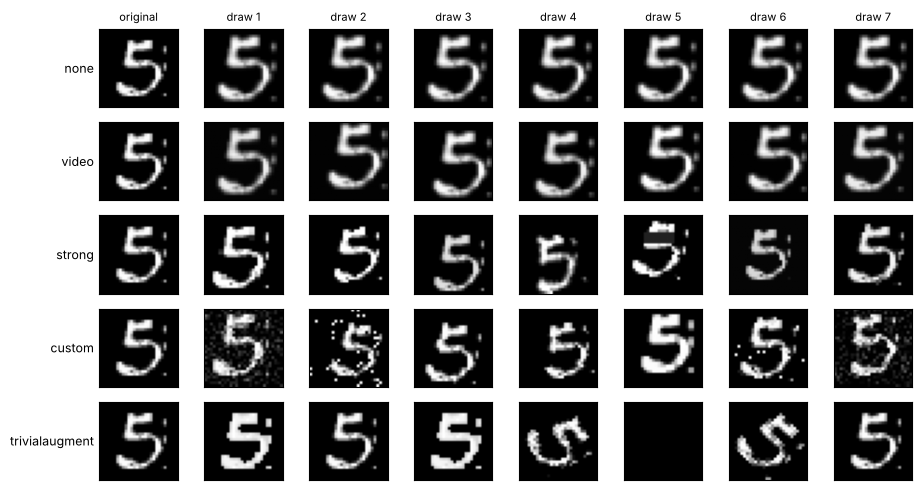

In [30]:
PIPELINES = {
    "none":           test_transform,            # baseline: no augmentation
    "video":          train_transform,           # Section 5
    "strong":         strong_transform,          # Section 6.4
    "custom":         custom_train_transform,    # Section 8
    "trivialaugment": v2.Compose([v2.ToImage(), v2.TrivialAugmentWide(),
                                  v2.ToDtype(torch.float32, scale=True), v2.Normalize((MEAN,), (STD,))]),
}
gallery(img, PIPELINES)

In [31]:
AUGMENTATION = "video"       # one of PIPELINES

dm = MnistDataModule(DATASET, DATA_PATH, BATCH_SIZE, NUM_WORKERS,
                     train_transform=PIPELINES[AUGMENTATION], test_transform=test_transform)

# ----------------------------------------------------------------------------
# Lightning training pipeline (LightningModule + Trainer) goes here
# ----------------------------------------------------------------------------

## 13. Exercises

1. **`RandomPixelate(v2.Transform)`:** downsample to $s\times s$ with $s\sim\mathcal{U}\{7,\dots,14\}$, then upsample back to $28\times28$ with nearest-neighbor interpolation (`F.interpolate`). Draw $s$ in `make_params`.
2. **`RandomScratch(v2.Transform)`:** draw 1–3 random straight white lines across the image, like pen slips or scanner artifacts.
3. **How much rotation is safe?** For MNIST, find the largest $\phi_{\max}$ in `RandomRotation(phi_max)` for which 6s and 9s stay distinguishable. Visualize 20 rotated 6s and 9s.
4. **Switch datasets:** set `DATASET = "FashionMNIST"` and rerun everything. Which transforms in Section 7 become label-preserving, and which stay harmful?
5. **Augmentation as hypothesis:** for each transform in Section 6, write one sentence on the invariance it encodes, and say whether that invariance holds for MNIST, Fashion-MNIST, and chest X-rays.

## References
* Chen, T., Kornblith, S., Norouzi, M., & Hinton, G. (2020). A simple framework for contrastive learning of visual representations. *ICML 2020*.
* Cubuk, E. D., Zoph, B., Mané, D., Vasudevan, V., & Le, Q. V. (2019). AutoAugment: Learning augmentation strategies from data. *CVPR 2019*.
* Cubuk, E. D., Zoph, B., Shlens, J., & Le, Q. V. (2020). RandAugment: Practical automated data augmentation with a reduced search space. *NeurIPS 2020*.
* DeVries, T., & Taylor, G. W. (2017). Improved regularization of convolutional neural networks with Cutout. *arXiv:1708.04552*.
* Hendrycks, D., Mu, N., Cubuk, E. D., Zoph, B., Gilmer, J., & Lakshminarayanan, B. (2020). AugMix: A simple data processing method to improve robustness and uncertainty. *ICLR 2020*.
* Müller, S. G., & Hutter, F. (2021). TrivialAugment: Tuning-free yet state-of-the-art data augmentation. *ICCV 2021*.
* Raschka, S. (2023). *Deep Learning Fundamentals*, Unit 7.5: Improving predictions with data augmentation. Lightning AI.
* Shorten, C., & Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data, 6*(1), 60.
* Simard, P. Y., Steinkraus, D., & Platt, J. C. (2003). Best practices for convolutional neural networks applied to visual document analysis. *ICDAR 2003*.
* Tian, Y., Sun, C., Poole, B., Krishnan, D., Schmid, C., & Isola, P. (2020). What makes for good views for contrastive learning? *NeurIPS 2020*.
* Yun, S., Han, D., Oh, S. J., Chun, S., Choe, J., & Yoo, Y. (2019). CutMix: Regularization strategy to train strong classifiers with localizable features. *ICCV 2019*.
* Zhang, H., Cisse, M., Dauphin, Y. N., & Lopez-Paz, D. (2018). mixup: Beyond empirical risk minimization. *ICLR 2018*.
* Zhong, Z., Zheng, L., Kang, G., Li, S., & Yang, Y. (2020). Random erasing data augmentation. *AAAI 2020*.